# 🔮 FORECAST_out_of_sample — Prediksi Volatilitas H+1 (dan Opsional H+N)
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### 🎯 Tujuan
Menghasilkan **ramalan volatilitas di luar data historis** (di luar `dataset_test`) menggunakan model XGBoost & LSTM yang sudah dilatih — untuk demo aplikasi praktis di Bab 4/5 tesis.

### ⚠️ Keterbatasan Metodologis yang HARUS Dicantumkan di Bab 5
Model memakai fitur eksogen (RSI, Stochastic, MA-ratio, sentimen berita) yang membutuhkan data harga & berita **hari itu sendiri** untuk dihitung. Konsekuensinya:

| Horizon | Validitas | Cara Fitur Diperoleh |
|---|---|---|
| **H+1** (besok) | ✅ **Valid penuh** — sama seperti evaluasi test set | Fitur dihitung dari data riil sampai hari ini |
| **H+2 s/d H+N** | ⚠️ **Naif/ilustratif** — bukan forecast riil | Volatilitas historis (Vol_Lag/MA/STD) diupdate rekursif dari prediksi sendiri; RSI/Stochastic/MA-Ratio/Sentimen **dibekukan** di nilai hari terakhir karena data harga & berita masa depan tidak tersedia |

Notebook ini TIDAK mengklaim H+2..H+N sebagai forecast valid secara akademik — ditandai jelas sebagai **skenario ilustratif dengan asumsi 'kondisi pasar tetap'**, dan errornya membesar tiap langkah (bukan untuk dilaporkan sebagai hasil utama RM-3, cukup sebagai pelengkap demo aplikasi di Bab 4).

---
## ⚙️ CELL 1 — Import, Konfigurasi Path, Fitur X1/X2/Y

In [1]:
import os, datetime, json as _json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras

SEED = 42
np.random.seed(SEED)

# ── ROOT auto-detect (identik notebook lain) ──
ROOT = Path(os.getcwd())
for _ in range(6):
    if (ROOT / '03_dataset').exists(): break
    ROOT = ROOT.parent
if not (ROOT / '03_dataset').exists():
    ROOT = Path(r'e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL     = ROOT / '03_dataset' / 'final'
DIR_XGB       = ROOT / '04_model' / 'xgboost'
DIR_LSTM      = ROOT / '04_model' / 'lstm'
DIR_TABEL     = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR    = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_TABEL, DIR_GAMBAR):
    d.mkdir(parents=True, exist_ok=True)

URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
# FIX v3: lookback BERBEDA per emiten (hasil CELL 4B tuning MODEL_lstm_v4).
LOOKBACK_DEFAULT = 10
def _muat_lookback_map():
    p = ROOT / '06_dokumen_tesis' / 'tabel' / 'tabel_hyperparameter_lstm.csv'
    peta = {e: LOOKBACK_DEFAULT for e in URUTAN_EMITEN}
    if not p.exists():
        print(f'  ⚠️  {p.name} tidak ada -> lookback {LOOKBACK_DEFAULT} untuk semua.')
        return peta
    d = pd.read_csv(p)
    kol_e = next((c for c in d.columns if c.lower() in ('emiten','kode_emiten')), None)
    kol_l = next((c for c in d.columns if 'lookback' in c.lower()), None)
    if kol_e and kol_l:
        for _, r in d.iterrows():
            if r[kol_e] in peta: peta[r[kol_e]] = int(r[kol_l])
        print(f'  ℹ️  Lookback per emiten: {peta}')
    return peta
LOOKBACK_MAP = _muat_lookback_map()
LOOKBACK = max(LOOKBACK_MAP.values())   # ambil terpanjang utk menyiapkan histori
N_HARI_FORECAST = 5    # untuk mode rekursif H+1..H+N (opsional, CELL 7)

def muat_csv(path, **kw):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File TIDAK ADA: {path.resolve()}')
    df = pd.read_csv(path, **kw)
    print(f'LOAD  : {path.resolve()}  ({len(df):,} baris x {df.shape[1]} kolom)')
    return df

# ── FIX konsisten dgn seluruh pipeline v2: KOLOM_X1/KOLOM_Y dari metadata PREP_01 ──
PATH_META_X1 = DIR_PROCESSED / 'technical_features_meta.json'
if PATH_META_X1.exists():
    with open(PATH_META_X1, 'r', encoding='utf-8') as f:
        _meta = _json.load(f)
    KOLOM_X1 = _meta['kolom_x1']
    KOLOM_Y  = _meta['kolom_y']
else:
    KOLOM_X1 = ['Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
                'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14',
                'Stoch_K', 'Stoch_D', 'Volume_ZScore']
    KOLOM_Y = 'Volatilitas_Target'

KOLOM_X2 = ['Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']
KOLOM_X = KOLOM_X1 + KOLOM_X2

print('='*66)
print('  🔮 FORECAST OUT-OF-SAMPLE — KONFIGURASI SIAP')
print('='*66)
print(f'ROOT       : {ROOT}')
print(f'KOLOM_X1   : {KOLOM_X1}')
print(f'KOLOM_X2   : {KOLOM_X2}')
print(f'KOLOM_Y    : {KOLOM_Y}')
print(f'LOOKBACK   : {LOOKBACK}')
print('='*66)


  ℹ️  Lookback per emiten: {'ADRO': 10, 'ADMR': 10, 'ITMG': 15, 'PTBA': 10, 'MEDC': 10, 'AKRA': 15, 'PGAS': 15}
  🔮 FORECAST OUT-OF-SAMPLE — KONFIGURASI SIAP
ROOT       : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
KOLOM_X1   : ['Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5', 'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14', 'Stoch_K', 'Stoch_D', 'Volume_ZScore']
KOLOM_X2   : ['Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']
KOLOM_Y    : Volatilitas_Target
LOOKBACK   : 15


---
## 🔧 CELL 2 — Fungsi Bantu: Forward/Inverse Transform, Kategori Risiko

In [2]:
def inverse_lstm(nilai_log):
    '''FIX v3 — KRITIS. MODEL_lstm_v4 dilatih pada LOG-TARGET: keluaran model
    adalah log(volatilitas). Pengembalian ke skala asli memakai exp(),
    BUKAN inverse MinMax. Salah transform di sini tidak memunculkan error,
    hanya angka prediksi yang keliru total.'''
    import numpy as _np
    return float(_np.exp(float(nilai_log)))

def forward_transform(nilai_asli, scaler_df, kolom):
    """Ubah nilai skala ASLI -> MinMax [0,1], pakai min/max HASIL TRAIN (PREP_03).
    Kebalikan dari inverse_transform. Dipakai untuk scale data TERBARU (belum
    pernah dilihat scaler) sebelum masuk model — TIDAK re-fit scaler (no leakage),
    murni transform pakai parameter yang sudah dikunci saat training."""
    if scaler_df is None or kolom not in scaler_df.index:
        return np.asarray(nilai_asli, dtype=float)
    cmin = float(scaler_df.loc[kolom, 'min']); cmax = float(scaler_df.loc[kolom, 'max'])
    rentang = (cmax - cmin) if (cmax - cmin) != 0 else 1.0
    hasil = (np.asarray(nilai_asli, dtype=float) - cmin) / rentang
    return np.clip(hasil, 0, 1)   # clip: nilai baru bisa saja di luar rentang train

def inverse_transform(nilai_scaled, scaler_df, kolom):
    """Kembalikan nilai ter-MinMax-scale ke skala asli. Identik seluruh notebook lain."""
    if scaler_df is None or kolom not in scaler_df.index:
        return np.asarray(nilai_scaled, dtype=float)
    cmin = float(scaler_df.loc[kolom, 'min']); cmax = float(scaler_df.loc[kolom, 'max'])
    return np.asarray(nilai_scaled, dtype=float) * (cmax - cmin) + cmin

def hitung_threshold_risiko(vol_historis_series, q_low=0.33, q_high=0.66):
    """Hitung threshold kuantil 33%/66% dari distribusi HISTORIS Volatilitas_Target
    untuk SATU emiten (per-emiten, bukan global) — skala volatilitas beda jauh
    antar emiten (mis. PGAS historis lebih stabil dari MEDC), threshold global
    akan bias ke emiten yang secara natural lebih/kurang volatil."""
    data = vol_historis_series.dropna()
    if data.empty:
        raise ValueError("Data historis volatilitas kosong — cek filter emiten.")
    q33 = data.quantile(q_low)
    q66 = data.quantile(q_high)
    return q33, q66


def kategori_risiko(vol, vol_historis_series):
    """Klasifikasi RULE-BASED (bukan model ML) — threshold kuantil 33%/66%
    dari distribusi historis Volatilitas_Target emiten yang sama. Label
    Inggris (Low/Medium/High Risk) untuk konsisten dengan istilah baku
    manajemen risiko keuangan di Bab 4/5 tesis."""
    q33, q66 = hitung_threshold_risiko(vol_historis_series)
    if vol < q33:
        return 'Low Risk'
    elif vol < q66:
        return 'Medium Risk'
    else:
        return 'High Risk'

print('✅ Fungsi bantu siap (forward/inverse transform, klasifikasi risiko kuantil per-emiten).')


✅ Fungsi bantu siap (forward/inverse transform, klasifikasi risiko kuantil per-emiten).


---
## 📂 CELL 3 — Ambil Data Terbaru per Emiten (untuk Forecast H+1)

Ambil `LOOKBACK` (10) hari bursa TERAKHIR dari `technical_features.csv` + `skor_sentimen_harian.csv` per emiten — baris paling akhir inilah yang jadi basis prediksi H+1 (besok, di luar data historis).

In [3]:
print('='*70)
print('  📂 CELL 3 — MUAT DATA TERBARU PER EMITEN')
print('='*70)

df_tek = muat_csv(DIR_PROCESSED / 'technical_features.csv')
df_tek['Date'] = pd.to_datetime(df_tek['Date'])

df_sen = muat_csv(DIR_PROCESSED / 'skor_sentimen_harian.csv')
df_sen['Date'] = pd.to_datetime(df_sen['Date'])

dict_terbaru = {}   # {emiten: DataFrame LOOKBACK baris terakhir, fitur lengkap}
dict_scaler  = {}

for emiten in URUTAN_EMITEN:
    d_tek = df_tek[df_tek['Emiten'] == emiten].sort_values('Date')
    d_sen = df_sen[df_sen['Emiten'] == emiten].sort_values('Date')

    d = pd.merge(d_tek, d_sen[['Date'] + KOLOM_X2], on='Date', how='left')
    for c in KOLOM_X2:
        d[c] = d[c].fillna(0.0 if c != 'Ada_Berita' else 0)

    kolom_hilang = [c for c in KOLOM_X1 + KOLOM_X2 if c not in d.columns]
    if kolom_hilang:
        print(f'  ⚠️  {emiten}: kolom hilang {kolom_hilang}, skip')
        continue

    d = d.dropna(subset=KOLOM_X1).reset_index(drop=True)
    if len(d) < LOOKBACK:
        print(f'  ⚠️  {emiten}: hanya {len(d)} baris valid (< LOOKBACK={LOOKBACK}), skip')
        continue

    p_sc = DIR_FINAL / f'scaler_params_{emiten}.csv'
    scaler = pd.read_csv(p_sc, index_col=0, encoding='utf-8-sig') if p_sc.exists() else None
    if scaler is None:
        print(f'  ⚠️  {emiten}: scaler_params tidak ditemukan, skip')
        continue

    dict_terbaru[emiten] = d.tail(LOOKBACK).reset_index(drop=True)
    dict_scaler[emiten]  = scaler

    tgl_terakhir = d['Date'].iloc[-1].date()
    print(f'  ✅ {emiten}: data s/d {tgl_terakhir} siap untuk forecast H+1 '
          f'({tgl_terakhir + pd.Timedelta(days=1)} kalender, sesuaikan hari bursa)')

print(f'\nTotal emiten siap: {len(dict_terbaru)}/{len(URUTAN_EMITEN)}')


  📂 CELL 3 — MUAT DATA TERBARU PER EMITEN
LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features.csv  (7,287 baris x 25 kolom)
LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\skor_sentimen_harian.csv  (7,308 baris x 6 kolom)
  ✅ ADRO: data s/d 2026-06-15 siap untuk forecast H+1 (2026-06-16 kalender, sesuaikan hari bursa)
  ✅ ADMR: data s/d 2026-06-15 siap untuk forecast H+1 (2026-06-16 kalender, sesuaikan hari bursa)
  ✅ ITMG: data s/d 2026-06-15 siap untuk forecast H+1 (2026-06-16 kalender, sesuaikan hari bursa)
  ✅ PTBA: data s/d 2026-06-15 siap untuk forecast H+1 (2026-06-16 kalender, sesuaikan hari bursa)
  ✅ MEDC: data s/d 2026-06-15 siap untuk forecast H+1 (2026-06-16 kalender, sesuaikan hari bursa)
  ✅ AKRA: data s/d 2026-06-15 siap untuk forecast H+1 (2026-06-

---
## 🌳 CELL 4 — Prediksi H+1 dengan XGBoost

Pakai **1 baris fitur terakhir** (hari bursa paling akhir) → model XGBoost (tidak butuh sequence, tabular). Ingat: model XGBoost dilatih dengan target ×100 (lihat `MODEL_xgboost_v2` CELL 5) — prediksi mentah dibagi 100 dulu sebelum *inverse-transform*, sama seperti di `EVALUASI_perbandingan_v2`.

In [4]:
print('='*70)
print('  🌳 CELL 4 — PREDIKSI H+1 — XGBOOST')
print('='*70)

hasil_xgb_h1 = {}

for emiten in dict_terbaru:
    path_mdl = DIR_XGB / f'xgboost_{emiten}.pkl'
    if not path_mdl.exists():
        print(f'  ⚠️  {emiten}: model XGBoost tidak ditemukan, skip'); continue

    model  = joblib.load(path_mdl)
    scaler = dict_scaler[emiten]
    baris_terakhir = dict_terbaru[emiten].iloc[[-1]]   # 1 baris terakhir (DataFrame, bukan Series)

    kolom_x = list(model.feature_names_in_) if hasattr(model, 'feature_names_in_') else KOLOM_X
    kolom_x_hilang = [c for c in kolom_x if c not in baris_terakhir.columns]
    if kolom_x_hilang:
        print(f'  ❌ {emiten}: fitur hilang {kolom_x_hilang}, skip'); continue

    # Scale fitur (forward transform, pakai scaler HASIL TRAIN — tidak re-fit)
    X_scaled = np.array([[forward_transform(baris_terakhir[c].values[0], scaler, c)
                           for c in kolom_x]])

    # KOREKSI v3.1: '/100' DIKEMBALIKAN. MODEL_xgboost_vv3 CELL 5 melatih pada
    # y*100, sehingga keluaran model berskala x100 dan harus dibagi 100 dulu.
    y_pred_scaled = model.predict(X_scaled)[0] / 100
    y_pred = float(np.clip(inverse_transform(y_pred_scaled, scaler, KOLOM_Y), 0, None))

    tgl_basis = baris_terakhir['Date'].values[0]
    hasil_xgb_h1[emiten] = {'Tanggal_Basis': pd.Timestamp(tgl_basis), 'Vol_Prediksi_H1': y_pred}
    print(f'  ✅ {emiten:<5}: basis={pd.Timestamp(tgl_basis).date()} → Vol_H+1 = {y_pred:.6f}')

print(f'\nTotal diprediksi: {len(hasil_xgb_h1)} emiten')


  🌳 CELL 4 — PREDIKSI H+1 — XGBOOST
  ✅ ADRO : basis=2026-06-15 → Vol_H+1 = 0.028828
  ✅ ADMR : basis=2026-06-15 → Vol_H+1 = 0.056082
  ✅ ITMG : basis=2026-06-15 → Vol_H+1 = 0.028090
  ✅ PTBA : basis=2026-06-15 → Vol_H+1 = 0.033930
  ✅ MEDC : basis=2026-06-15 → Vol_H+1 = 0.049737
  ✅ AKRA : basis=2026-06-15 → Vol_H+1 = 0.029845
  ✅ PGAS : basis=2026-06-15 → Vol_H+1 = 0.032009

Total diprediksi: 7 emiten


---
## 🧠 CELL 5 — Prediksi H+1 dengan LSTM

Pakai **sequence 10 hari terakhir** (LOOKBACK) → model LSTM. Tidak ada trik ×100 di sini (LSTM dilatih langsung di skala MinMax [0,1]).

In [5]:
print('='*70)
print('  🧠 CELL 5 — PREDIKSI H+1 — LSTM')
print('='*70)

hasil_lstm_h1 = {}

for emiten in dict_terbaru:
    path_mdl = DIR_LSTM / f'lstm_best_{emiten}.keras'
    if not path_mdl.exists():
        print(f'  ⚠️  {emiten}: model LSTM tidak ditemukan, skip'); continue

    model  = keras.models.load_model(path_mdl, compile=False)
    scaler = dict_scaler[emiten]
    _lb    = LOOKBACK_MAP.get(emiten, LOOKBACK_DEFAULT)   # FIX v3: per emiten
    seq_df = dict_terbaru[emiten].iloc[-_lb:]   # _lb baris terakhir, kronologis

    n_exp = model.input_shape[-1]
    if n_exp != len(KOLOM_X):
        print(f'  ❌ {emiten}: fitur LSTM ({len(KOLOM_X)}) != input model ({n_exp}), skip'); continue

    X_scaled = np.array([[forward_transform(seq_df[c].values[i], scaler, c)
                           for c in KOLOM_X]
                          for i in range(len(seq_df))])
    X_scaled = X_scaled[np.newaxis, :, :]   # shape (1, LOOKBACK, n_fitur)

    y_pred_scaled = model.predict(X_scaled, verbose=0).flatten()[0]
    # FIX v3 KRITIS: keluaran LSTM v4 = LOG volatilitas -> exp(), bukan MinMax.
    y_pred = float(np.clip(inverse_lstm(y_pred_scaled), 0, None))

    tgl_basis = seq_df['Date'].iloc[-1]
    hasil_lstm_h1[emiten] = {'Tanggal_Basis': pd.Timestamp(tgl_basis), 'Vol_Prediksi_H1': y_pred}
    print(f'  ✅ {emiten:<5}: basis={pd.Timestamp(tgl_basis).date()} → Vol_H+1 = {y_pred:.6f}')

print(f'\nTotal diprediksi: {len(hasil_lstm_h1)} emiten')


  🧠 CELL 5 — PREDIKSI H+1 — LSTM
  ✅ ADRO : basis=2026-06-15 → Vol_H+1 = 0.025041
  ✅ ADMR : basis=2026-06-15 → Vol_H+1 = 0.054962
  ✅ ITMG : basis=2026-06-15 → Vol_H+1 = 0.025486
  ✅ PTBA : basis=2026-06-15 → Vol_H+1 = 0.031615
  ✅ MEDC : basis=2026-06-15 → Vol_H+1 = 0.050598
  ✅ AKRA : basis=2026-06-15 → Vol_H+1 = 0.025716
  ✅ PGAS : basis=2026-06-15 → Vol_H+1 = 0.028509

Total diprediksi: 7 emiten


---
## 📋 CELL 6 — Tabel Ringkasan Forecast H+1 (→ Tabel 4.X Tesis)

In [6]:
print('='*70)
print('  FORECAST H+1 — XGBoost vs LSTM + KLASIFIKASI RISIKO')
print('='*70)

baris = []
for emiten in URUTAN_EMITEN:
    if emiten not in hasil_xgb_h1 or emiten not in hasil_lstm_h1:
        continue
    d_hist = df_tek[df_tek['Emiten'] == emiten][KOLOM_Y].dropna()  # basis kuantil: Volatilitas_Target historis

    v_xgb  = hasil_xgb_h1[emiten]['Vol_Prediksi_H1']
    v_lstm = hasil_lstm_h1[emiten]['Vol_Prediksi_H1']
    tgl    = hasil_xgb_h1[emiten]['Tanggal_Basis']

    q33, q66 = hitung_threshold_risiko(d_hist)
    risiko_xgb  = kategori_risiko(v_xgb, d_hist)
    risiko_lstm = kategori_risiko(v_lstm, d_hist)

    # ── Format output ringkas per emiten (sesuai spesifikasi) ──
    print(f"Emiten               : {emiten}")
    print(f"Prediksi Volatilitas : XGBoost={v_xgb:.4f}  |  LSTM={v_lstm:.4f}")
    print(f"Kategori Risiko      : XGBoost={risiko_xgb}  |  LSTM={risiko_lstm}")
    print(f"  (threshold {emiten}: Q33={q33:.4f}, Q66={q66:.4f})")
    print('-' * 70)

    baris.append({
        'Emiten': emiten,
        'Basis (hari terakhir data)': tgl.date(),
        'Vol_Prediksi_XGBoost': round(v_xgb, 6),
        'Vol_Prediksi_LSTM': round(v_lstm, 6),
        'Selisih_Absolut': round(abs(v_xgb - v_lstm), 6),
        'Threshold_Q33': round(q33, 6),
        'Threshold_Q66': round(q66, 6),
        'Kategori_Risiko_XGB': risiko_xgb,
        'Kategori_Risiko_LSTM': risiko_lstm,
    })

df_forecast_h1 = pd.DataFrame(baris)
pd.set_option('display.width', 220, 'display.max_columns', None)
print()
print(df_forecast_h1.to_string(index=False))

path_out = DIR_TABEL / 'tabel_forecast_h1.csv'
df_forecast_h1.to_csv(path_out, index=False, encoding='utf-8-sig')
print(f'\n💾 Tabel disimpan: {path_out}')
print('\n⚠️  Ini prediksi H+1 (1 hari bursa ke depan dari data terakhir) — VALID PENUH,')
print('   dihitung dari fitur riil sampai hari terakhir data historis.')
print('ℹ️  Kategori risiko: rule-based (bukan model ML), threshold kuantil')
print('   33%/66% dari distribusi historis Volatilitas_Target PER EMITEN.')


  FORECAST H+1 — XGBoost vs LSTM + KLASIFIKASI RISIKO
Emiten               : ADRO
Prediksi Volatilitas : XGBoost=0.0288  |  LSTM=0.0250
Kategori Risiko      : XGBoost=High Risk  |  LSTM=Medium Risk
  (threshold ADRO: Q33=0.0200, Q66=0.0260)
----------------------------------------------------------------------
Emiten               : ADMR
Prediksi Volatilitas : XGBoost=0.0561  |  LSTM=0.0550
Kategori Risiko      : XGBoost=High Risk  |  LSTM=High Risk
  (threshold ADMR: Q33=0.0277, Q66=0.0371)
----------------------------------------------------------------------
Emiten               : ITMG
Prediksi Volatilitas : XGBoost=0.0281  |  LSTM=0.0255
Kategori Risiko      : XGBoost=High Risk  |  LSTM=High Risk
  (threshold ITMG: Q33=0.0131, Q66=0.0210)
----------------------------------------------------------------------
Emiten               : PTBA
Prediksi Volatilitas : XGBoost=0.0339  |  LSTM=0.0316
Kategori Risiko      : XGBoost=High Risk  |  LSTM=High Risk
  (threshold PTBA: Q33=0.0150, Q66

---
## ⚠️ CELL 7 (OPSIONAL) — Forecast Rekursif H+1..H+N (LSTM)

**BUKAN forecast valid secara akademik** — hanya demo ilustratif skenario "kondisi pasar tetap". Cara kerja tiap langkah rekursif:
- `Vol_Lag1/2/3, Vol_MA5, Vol_STD5` **diupdate** dari prediksi langkah sebelumnya (konsisten, karena ini murni fungsi dari volatilitas masa lalu)
- `RSI14, Stoch_K, Stoch_D, MA*_Ratio, Log_Return` **DIBEKUKAN** di nilai hari terakhir (asumsi harga tidak bergerak — TIDAK REALISTIS untuk H>1)
- `Sentiment_*` **DIBEKUKAN** di nilai hari terakhir (asumsi tidak ada berita baru)

Error membesar cepat tiap langkah karena asumsi "beku" ini. **Jangan** dilaporkan sebagai hasil utama RM-3 — cukup sebagai ilustrasi tren di Bab 4.

In [7]:
JALANKAN_MODE_REKURSIF = True   # set False untuk skip cell ini

if JALANKAN_MODE_REKURSIF:
    print('='*70)
    print(f'  ⚠️  CELL 7 — FORECAST REKURSIF H+1..H+{N_HARI_FORECAST} (ILUSTRATIF, LSTM)')
    print('='*70)
    print('  ⚠️  BUKAN forecast valid — asumsi fitur non-volatilitas BEKU. Lihat CELL 7 markdown.\n')

    hasil_rekursif = {}

    for emiten in dict_terbaru:
        path_mdl = DIR_LSTM / f'lstm_best_{emiten}.keras'
        if not path_mdl.exists():
            continue
        model  = keras.models.load_model(path_mdl, compile=False)
        scaler = dict_scaler[emiten]
        seq_df = dict_terbaru[emiten].copy().reset_index(drop=True)

        tgl_basis = seq_df['Date'].iloc[-1]
        proyeksi = []

        for h in range(1, N_HARI_FORECAST + 1):
            X_scaled = np.array([[forward_transform(seq_df[c].values[i], scaler, c)
                                   for c in KOLOM_X]
                                  for i in range(len(seq_df))])[np.newaxis, :, :]

            y_pred_scaled = model.predict(X_scaled, verbose=0).flatten()[0]
            y_pred = float(np.clip(inverse_transform(y_pred_scaled, scaler, KOLOM_Y), 0, None))

            proyeksi.append({'H': h, 'Tanggal_Estimasi': tgl_basis + pd.Timedelta(days=h),
                              'Vol_Prediksi': y_pred})

            # ── Update baris baru: geser window, fitur volatilitas terupdate,
            #    fitur lain DIBEKUKAN (copy baris terakhir) ──
            baris_baru = seq_df.iloc[[-1]].copy()
            baris_baru['Date'] = tgl_basis + pd.Timedelta(days=h)
            baris_baru['Vol_Lag3'] = seq_df['Vol_Lag2'].values[-1]
            baris_baru['Vol_Lag2'] = seq_df['Vol_Lag1'].values[-1]
            baris_baru['Vol_Lag1'] = y_pred
            vol5 = list(seq_df['Vol_Lag1'].values[-4:]) + [y_pred]
            baris_baru['Vol_MA5']  = np.mean(vol5)
            baris_baru['Vol_STD5'] = np.std(vol5)
            # RSI14, Stoch_K/D, MA*_Ratio, Log_Return, Sentiment_* : TETAP (dibekukan)

            seq_df = pd.concat([seq_df.iloc[1:], baris_baru], ignore_index=True)

        hasil_rekursif[emiten] = pd.DataFrame(proyeksi)
        print(f'  {emiten}: ' + ' | '.join(
            f"H+{r['H']}={r['Vol_Prediksi']:.5f}" for _, r in hasil_rekursif[emiten].iterrows()))

    df_rekursif_all = pd.concat(
        [df.assign(Emiten=e) for e, df in hasil_rekursif.items()], ignore_index=True
    )
    path_rek = DIR_TABEL / 'tabel_forecast_rekursif_ilustratif.csv'
    df_rekursif_all.to_csv(path_rek, index=False, encoding='utf-8-sig')
    print(f'\n💾 Tabel disimpan: {path_rek}')
    print('⚠️  INGAT: tandai tabel ini "ILUSTRATIF" di Bab 4 — bukan hasil forecast utama.')
else:
    print('Mode rekursif dilewati (JALANKAN_MODE_REKURSIF=False).')


  ⚠️  CELL 7 — FORECAST REKURSIF H+1..H+5 (ILUSTRATIF, LSTM)
  ⚠️  BUKAN forecast valid — asumsi fitur non-volatilitas BEKU. Lihat CELL 7 markdown.

  ADRO: H+1=0.00000 | H+2=0.00000 | H+3=0.00000 | H+4=0.00000 | H+5=0.00000
  ADMR: H+1=0.00000 | H+2=0.00000 | H+3=0.00000 | H+4=0.00000 | H+5=0.00000
  ITMG: H+1=0.00000 | H+2=0.00000 | H+3=0.00000 | H+4=0.00000 | H+5=0.00000
  PTBA: H+1=0.00000 | H+2=0.00000 | H+3=0.00000 | H+4=0.00000 | H+5=0.00000
  MEDC: H+1=0.00000 | H+2=0.00000 | H+3=0.00000 | H+4=0.00000 | H+5=0.00000
  AKRA: H+1=0.00000 | H+2=0.00000 | H+3=0.00000 | H+4=0.00000 | H+5=0.00000
  PGAS: H+1=0.00000 | H+2=0.00000 | H+3=0.00000 | H+4=0.00000 | H+5=0.00000

💾 Tabel disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\tabel\tabel_forecast_rekursif_ilustratif.csv
⚠️  INGAT: tandai tabel ini "ILUSTRATIF" di Bab 4 — bukan hasil forecast utama.


---
## 📊 CELL 8 — Visualisasi: Historis + Forecast H+1 (+ Rekursif Ilustratif)

  📊 VISUALISASI FORECAST PER EMITEN (VERSI DIPERBARUI)


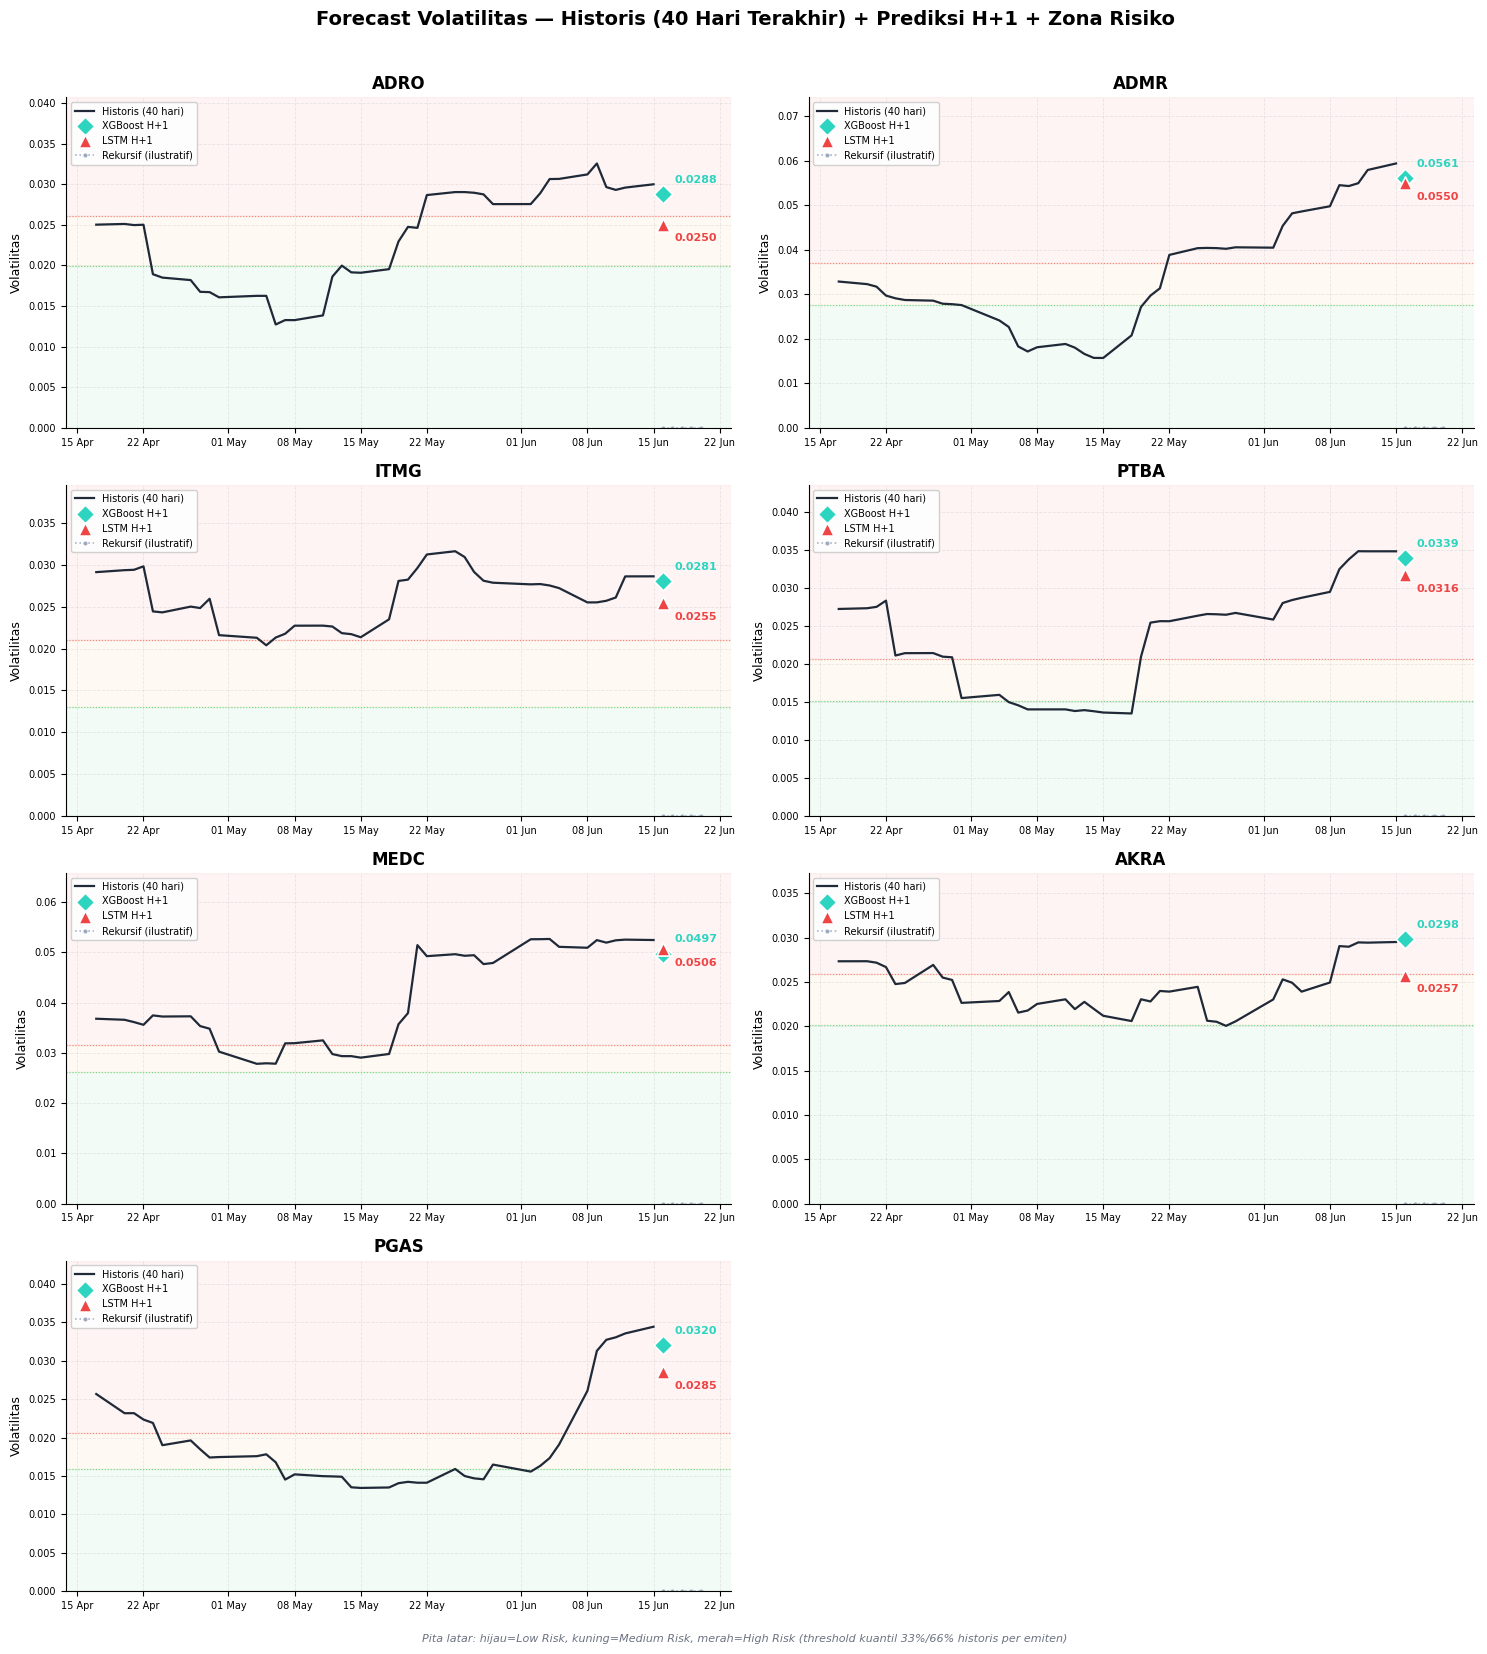

💾 Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_forecast_out_of_sample.png

✅ FORECAST OUT-OF-SAMPLE SELESAI
   H+1 (valid)        : tabel_forecast_h1.csv
   H+1..H+N (ilustratif): tabel_forecast_rekursif_ilustratif.csv


In [8]:
print('='*70)
print('  📊 VISUALISASI FORECAST PER EMITEN (VERSI DIPERBARUI)')
print('='*70)

import matplotlib.dates as mdates

# ── Palet warna konsisten dengan dashboard (Low=hijau, Medium=amber, High=merah) ──
WARNA = {
    'historis': '#1f2937',      # abu gelap netral, bukan biru default matplotlib
    'xgboost':  '#2DD4BF',      # teal — aksen model utama
    'lstm':     '#EF4444',      # merah — model pembanding
    'rekursif': '#94A3B8',      # abu terang, garis putus-putus
    'zona_low':    '#22C55E',
    'zona_medium': '#F5A623',
    'zona_high':   '#EF4444',
}

emiten_ok = [e for e in URUTAN_EMITEN if e in hasil_xgb_h1 and e in hasil_lstm_h1]
ncol = 2; nrow = int(np.ceil(len(emiten_ok) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 4 * nrow))
axes = np.array(axes).ravel()

for ax, emiten in zip(axes, emiten_ok):
    d_hist = df_tek[df_tek['Emiten'] == emiten].sort_values('Date').tail(40)
    hist_vol = df_tek[df_tek['Emiten'] == emiten][KOLOM_Y].dropna()  # basis kuantil, sama seperti CELL 6

    # ── Pita latar zona risiko (Low/Medium/High) — konteks visual langsung ──
    q33, q66 = hitung_threshold_risiko(hist_vol)
    y_max_plot = max(d_hist['Volatilitas'].max(),
                      hasil_xgb_h1[emiten]['Vol_Prediksi_H1'],
                      hasil_lstm_h1[emiten]['Vol_Prediksi_H1']) * 1.25
    ax.axhspan(0, q33, color=WARNA['zona_low'], alpha=0.06, zorder=0)
    ax.axhspan(q33, q66, color=WARNA['zona_medium'], alpha=0.06, zorder=0)
    ax.axhspan(q66, y_max_plot, color=WARNA['zona_high'], alpha=0.06, zorder=0)

    # ── Garis historis ──
    ax.plot(d_hist['Date'], d_hist['Volatilitas'], color=WARNA['historis'],
             lw=1.6, label='Historis (40 hari)', zorder=5)

    # ── Titik prediksi H+1, dengan label nilai langsung di grafik ──
    tgl_h1 = hasil_xgb_h1[emiten]['Tanggal_Basis'] + pd.Timedelta(days=1)
    v_xgb  = hasil_xgb_h1[emiten]['Vol_Prediksi_H1']
    v_lstm = hasil_lstm_h1[emiten]['Vol_Prediksi_H1']

    ax.scatter([tgl_h1], [v_xgb], color=WARNA['xgboost'], marker='D', s=90,
               zorder=6, edgecolor='white', linewidth=1.2, label='XGBoost H+1')
    ax.annotate(f'{v_xgb:.4f}', xy=(tgl_h1, v_xgb), xytext=(8, 8),
                textcoords='offset points', fontsize=8, fontweight='bold',
                color=WARNA['xgboost'])

    ax.scatter([tgl_h1], [v_lstm], color=WARNA['lstm'], marker='^', s=90,
               zorder=6, edgecolor='white', linewidth=1.2, label='LSTM H+1')
    ax.annotate(f'{v_lstm:.4f}', xy=(tgl_h1, v_lstm), xytext=(8, -12),
                textcoords='offset points', fontsize=8, fontweight='bold',
                color=WARNA['lstm'])

    # ── Garis putus threshold Q33/Q66 (referensi visual batas zona) ──
    ax.axhline(q33, color=WARNA['zona_low'], lw=0.8, ls=':', alpha=0.6)
    ax.axhline(q66, color=WARNA['zona_high'], lw=0.8, ls=':', alpha=0.6)

    # ── Rekursif ilustratif (kalau aktif) ──
    if JALANKAN_MODE_REKURSIF and emiten in hasil_rekursif:
        dfr = hasil_rekursif[emiten]
        ax.plot(dfr['Tanggal_Estimasi'], dfr['Vol_Prediksi'],
                color=WARNA['rekursif'], lw=1.2, linestyle=':', marker='.',
                markersize=4, alpha=0.8, label='Rekursif (ilustratif)')

    ax.set_title(emiten, fontweight='bold', fontsize=12)
    ax.set_ylabel('Volatilitas', fontsize=9)
    ax.set_ylim(0, y_max_plot)
    ax.legend(fontsize=7, loc='upper left', framealpha=0.9)
    ax.tick_params(labelsize=7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.grid(alpha=0.25, linestyle='--', linewidth=0.6)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

for ax in axes[len(emiten_ok):]:
    ax.axis('off')

fig.suptitle('Forecast Volatilitas — Historis (40 Hari Terakhir) + Prediksi H+1 + Zona Risiko',
             fontweight='bold', fontsize=14, y=1.01)
fig.text(0.5, -0.01,
         'Pita latar: hijau=Low Risk, kuning=Medium Risk, merah=High Risk (threshold kuantil 33%/66% historis per emiten)',
         ha='center', fontsize=8, style='italic', color='#6b7280')

plt.tight_layout()
path_fig = DIR_GAMBAR / 'gambar_forecast_out_of_sample.png'
plt.savefig(path_fig, dpi=200, bbox_inches='tight')
plt.show()
print(f'💾 Gambar disimpan: {path_fig}')

print()
print('='*70)
print('✅ FORECAST OUT-OF-SAMPLE SELESAI')
print(f'   H+1 (valid)        : tabel_forecast_h1.csv')
if JALANKAN_MODE_REKURSIF:
    print(f'   H+1..H+N (ilustratif): tabel_forecast_rekursif_ilustratif.csv')
print('='*70)